# Лабораторная работа №3. Оптимизация гиперпараметров

Задача из первой лабы — предсказание качества вина. Модель — `GradientBoostingRegressor`.
`data/winequality_final.csv`
Сначала измеряем baseline на данных обучения, затем выполняем подбор с разбиением данных.


In [1]:
from pathlib import Path
from time import perf_counter

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import loguniform
from sklearn.base import clone
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import (
    train_test_split, KFold, cross_val_score,
    GridSearchCV, RandomizedSearchCV, validation_curve,
)

data_path = Path('data/winequality_final.csv')
if not data_path.exists():
    data_path = Path('lab3_mai/data/winequality_final.csv')
df = pd.read_csv(data_path, index_col='sample_id', float_precision='round_trip')
X, y = df.drop(columns='quality'), df['quality']
print('Объектов:', len(X), 'Признаков:', X.shape[1])


Объектов: 5320 Признаков: 67


C:\Users\Redmi\AppData\Local\Temp\ipykernel_15952\1309089358.py:19: Pandas4Warning: The 'float_precision' argument is deprecated. Use the default float precision instead.
  df = pd.read_csv(data_path, index_col='sample_id', float_precision='round_trip')


## Распределения данных

Качество и цвет вина, затем все 66 сплайновых признаков сохранённого датасета.


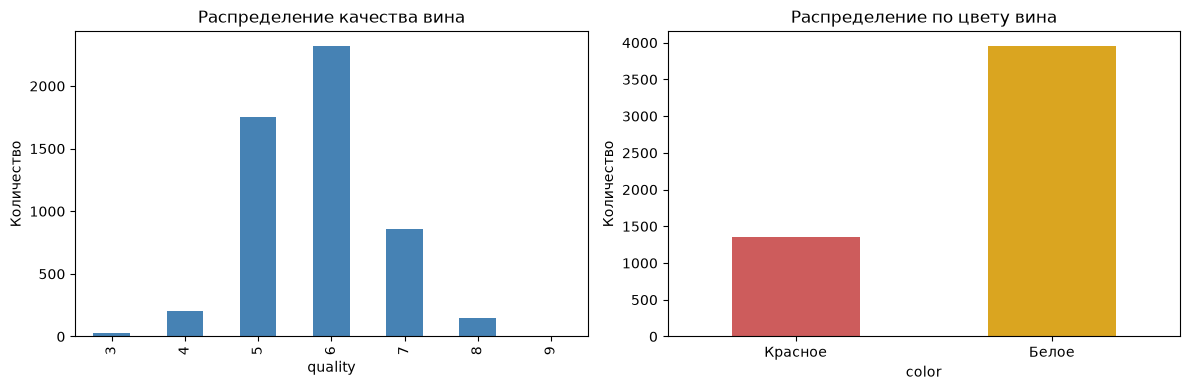

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df['quality'].value_counts().sort_index().plot.bar(ax=axes[0], color='steelblue')
axes[0].set(title='Распределение качества вина', xlabel='quality', ylabel='Количество')
df['color'].value_counts().reindex([0, 1]).plot.bar(
    ax=axes[1], color=['indianred', 'goldenrod'])
axes[1].set_xticklabels(['Красное', 'Белое'], rotation=0)
axes[1].set(title='Распределение по цвету вина', xlabel='color', ylabel='Количество')
plt.tight_layout()
plt.show()


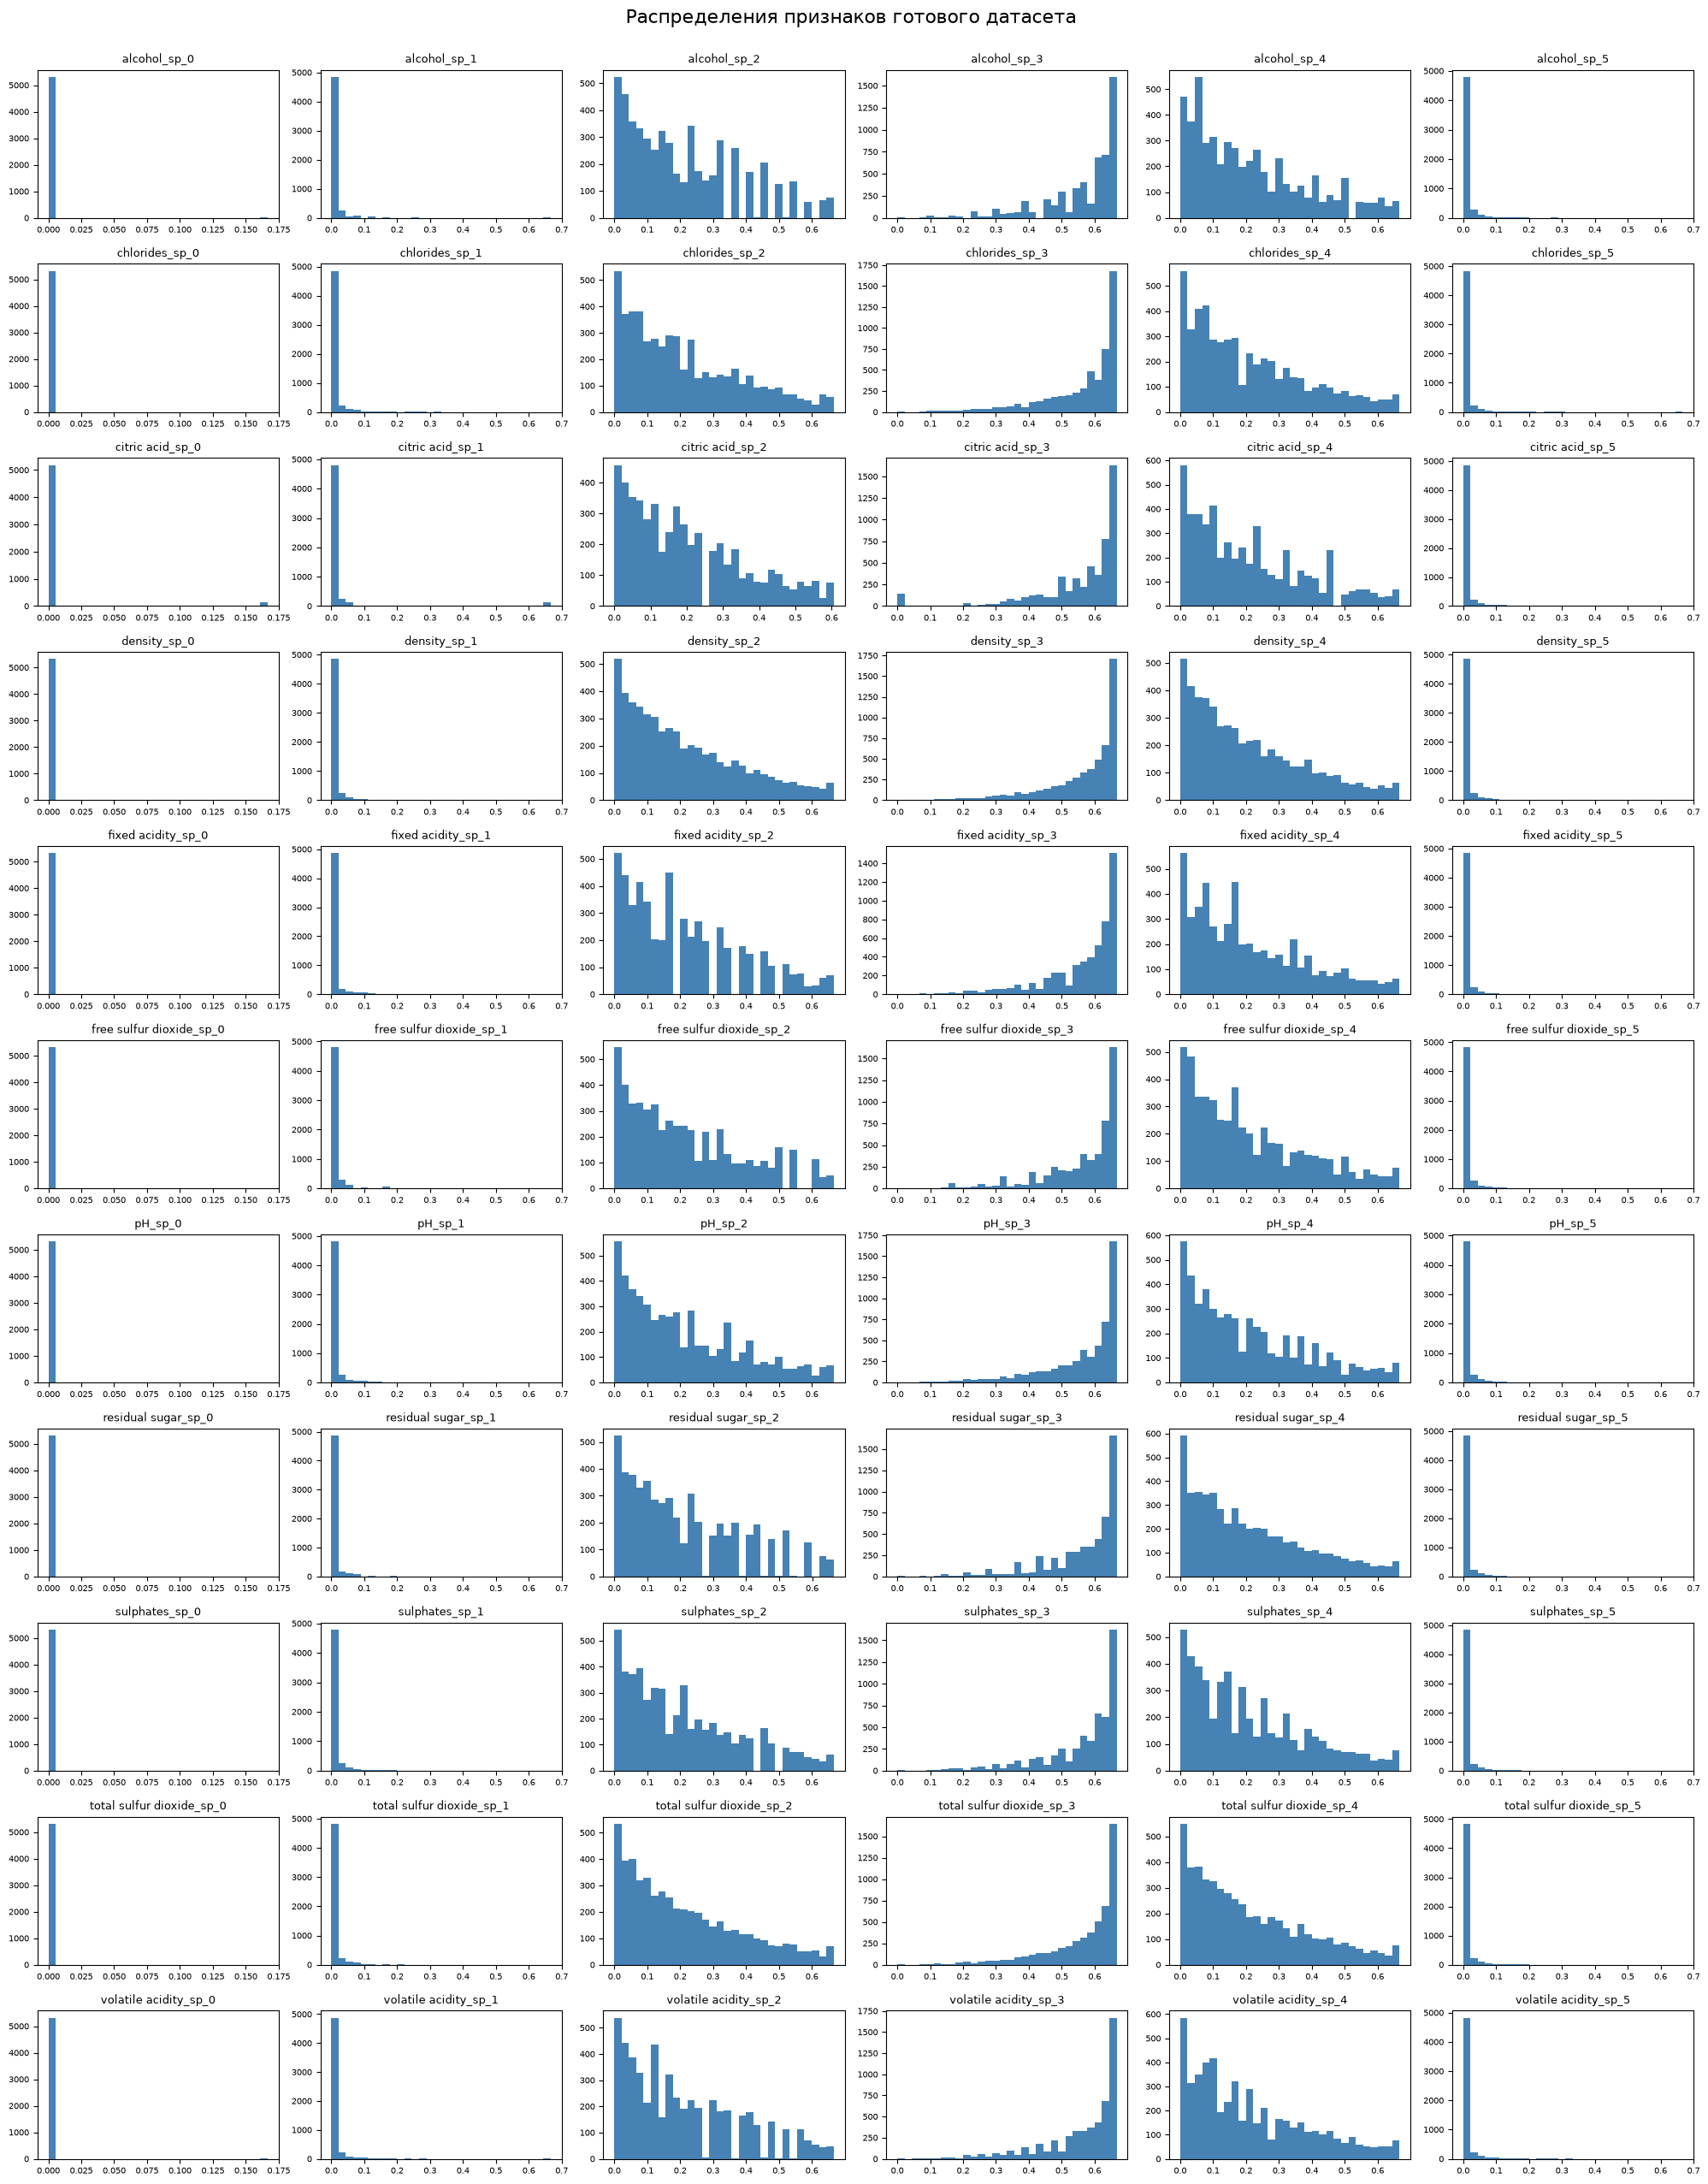

In [3]:
axes = X.drop(columns='color').hist(
    bins=30, layout=(11, 6), figsize=(20, 26), grid=False, color='steelblue')
for ax in axes.flat:
    ax.set_title(ax.get_title(), fontsize=9)
    ax.tick_params(labelsize=7)
plt.suptitle('Распределения признаков готового датасета', fontsize=16)
plt.tight_layout(rect=(0, 0, 1, 0.98))
plt.show()


## 1. Исходная модель и baseline

Исходные параметры из первой лабы: `n_estimators=100`, `learning_rate=0.1`,
`max_depth=3`, `random_state=3`. Обучаем на всём датасете и оцениваем на нём же.


In [4]:
model = GradientBoostingRegressor(
    n_estimators=100, learning_rate=0.1, max_depth=3, random_state=3)
baseline_full = clone(model).fit(X, y)
baseline_rmse = root_mean_squared_error(y, baseline_full.predict(X))
print(f'Baseline RMSE на данных обучения: {baseline_rmse:.4f}')


Baseline RMSE на данных обучения: 0.6437


Baseline на всех данных даёт RMSE **0,6437**. Это ошибка на обучении, поэтому она
оптимистична. Для сравнения CV и test по заданию ниже также оцениваем исходные
параметры на том же разбиении, что и результаты поиска.


## 2. Разбиение и кросс-валидация

Train — 70%, validation — 15%, test — 15%. В поисках используем одинаковую
5-fold CV на train.
Validation используется для выбора конфигурации, test — для финальной проверки.


In [5]:
train_val, test = train_test_split(df, test_size=0.15, random_state=3)
train, val = train_test_split(train_val, test_size=0.15 / 0.85, random_state=3)
X_train, y_train = train.drop(columns='quality'), train['quality']
X_val, y_val = val.drop(columns='quality'), val['quality']
cv = KFold(n_splits=5, shuffle=True, random_state=3)
scoring = 'neg_root_mean_squared_error'
initial_cv = -cross_val_score(model, X_train, y_train, cv=cv, scoring=scoring, n_jobs=4)
print('Train:', len(train), 'Validation:', len(val), 'Test:', len(test))
print(f'Исходная модель: CV RMSE {initial_cv.mean():.4f} ± {initial_cv.std():.4f}')


Train: 3724 Validation: 798 Test: 798
Исходная модель: CV RMSE 0.7140 ± 0.0109


## 3. Гиперпараметры

| Параметр | Смысл | Диапазон поиска | Ожидаемое влияние |
|---|---|---|---|
| `n_estimators` | Число деревьев | 50, 100, 200 | Мало — недообучение; много — больше затрат и риск переобучения |
| `learning_rate` | Вклад нового дерева | Grid: 0.03, 0.1, 0.2; Random: 0.02–0.3 по логарифмической шкале | Малый шаг требует больше деревьев, большой может ухудшить обобщение |
| `max_depth` | Глубина дерева | 2, 3 | Большая глубина позволяет изучать сложные зависимости, но увеличивает риск переобучения |


## 4. Grid Search


In [6]:
param_grid = {
    'n_estimators': [50, 100, 200],
    'learning_rate': [0.03, 0.1, 0.2],
    'max_depth': [2, 3],
}
grid = GridSearchCV(model, param_grid, cv=cv, scoring=scoring, n_jobs=4, refit=False)
started = perf_counter()
grid.fit(X_train, y_train)
grid_time = perf_counter() - started
print('Комбинаций:', len(grid.cv_results_['params']))
print('Лучшие параметры:', grid.best_params_)
print(f'CV RMSE: {-grid.best_score_:.4f}; время: {grid_time:.2f} с')


Комбинаций: 18
Лучшие параметры: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100}
CV RMSE: 0.7140; время: 66.78 с


## 5. Random Search

Число и глубина деревьев берутся из тех же диапазонов, шаг обучения — из
логарифмически равномерного распределения. Бюджет равен по числу обучений;
фактическое время может отличаться из-за выбранных комбинаций.


In [7]:
param_distributions = {
    'n_estimators': [50, 100, 200],
    'learning_rate': loguniform(0.02, 0.3),
    'max_depth': [2, 3],
}
random = RandomizedSearchCV(
    model, param_distributions, n_iter=18, cv=cv, scoring=scoring,
    random_state=3, n_jobs=4, refit=False)
started = perf_counter()
random.fit(X_train, y_train)
random_time = perf_counter() - started
print('Лучшие параметры:', random.best_params_)
display(pd.DataFrame({
    'Комбинаций': [len(grid.cv_results_['params']), len(random.cv_results_['params'])],
    'CV RMSE': [-grid.best_score_, -random.best_score_],
    'Время, с': [grid_time, random_time],
}, index=['Grid Search', 'Random Search']).round(4))


Лучшие параметры: {'learning_rate': np.float64(0.06154983387458399), 'max_depth': 3, 'n_estimators': 200}


,Комбинаций,CV RMSE,"Время, с"
Grid Search,18,0.7140,66.7814
Random Search,18,0.7132,59.8281


**Когда Random Search предпочтительнее полного перебора?** При широких диапазонах
и небольшом бюджете, особенно если важны лишь несколько параметров. Случайный
поиск пробует больше различных значений, тогда как размер сетки растёт как
произведение числа значений всех параметров. Здесь Random Search дал немного
меньшую CV RMSE: **0,7132** против **0,7140**, при одинаковых 18 комбинациях.


## 6. Влияние гиперпараметров

Меняем один параметр, остальные оставляем исходными. Для выявления недообучения
и переобучения используем более широкий диапазон. Эти графики строятся только
на train и не меняют пространство поиска.


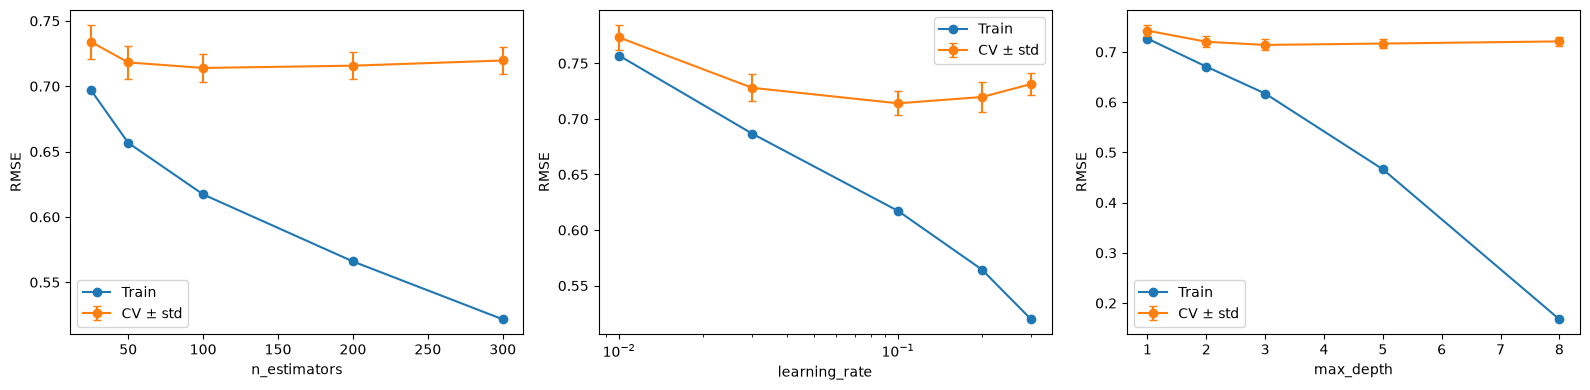

In [8]:
ranges = {
    'n_estimators': [25, 50, 100, 200, 300],
    'learning_rate': [0.01, 0.03, 0.1, 0.2, 0.3],
    'max_depth': [1, 2, 3, 5, 8],
}
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (parameter, values) in zip(axes, ranges.items()):
    train_scores, cv_scores = validation_curve(
        model, X_train, y_train, param_name=parameter, param_range=values,
        cv=cv, scoring=scoring, n_jobs=4)
    ax.plot(values, -train_scores.mean(axis=1), 'o-', label='Train')
    ax.errorbar(values, -cv_scores.mean(axis=1), yerr=cv_scores.std(axis=1),
                fmt='o-', capsize=3, label='CV ± std')
    ax.set(xlabel=parameter, ylabel='RMSE')
    if parameter == 'learning_rate':
        ax.set_xscale('log')
    ax.legend()
plt.tight_layout()
plt.show()


**Где наблюдается недообучение?** При глубине 1, малом числе деревьев или шаге
обучения 0,01 ошибки train и CV повышены: модель недостаточно хорошо описывает данные.


**Какая сложность выглядит разумной?** В исследованных срезах минимальная CV RMSE
получена около 100 деревьев, `learning_rate=0.1` и глубины 3. Увеличение сложности
после этих значений заметного улучшения CV не даёт.


**Где наблюдается переобучение и почему?** При глубинах 5–8 и большом числе деревьев
ошибка train снижается, а CV перестаёт улучшаться или растёт. Модель точнее описывает
обучающие объекты, но хуже переносит эти зависимости на новые. Шаг обучения и число
деревьев связаны: маленькому шагу обычно нужно больше деревьев.


## 7. Финальная модель

Сравниваем исходные параметры и победителей поисков на validation. Выбираем
конфигурацию по validation RMSE, затем переобучаем на train + validation.
Для отчёта оцениваем все три фиксированные конфигурации на test.


In [9]:
models = {
    'Исходная модель': clone(model),
    'Grid Search': clone(model).set_params(**grid.best_params_),
    'Random Search': clone(model).set_params(**random.best_params_),
}
validation_rmse = {}
for name, estimator in models.items():
    estimator.fit(X_train, y_train)
    validation_rmse[name] = root_mean_squared_error(y_val, estimator.predict(X_val))
selected = min(validation_rmse, key=validation_rmse.get)
display(pd.Series(validation_rmse, name='Validation RMSE').round(4))
print('Выбор до оценки на test:', selected)


Исходная модель    0.6854
Grid Search        0.6854
Random Search      0.6875
Name: Validation RMSE, dtype: float64

Выбор до оценки на test: Исходная модель


In [10]:
X_train_val, y_train_val = train_val.drop(columns='quality'), train_val['quality']
X_test, y_test = test.drop(columns='quality'), test['quality']
test_rmse = {}
for name, estimator in models.items():
    estimator.fit(X_train_val, y_train_val)
    test_rmse[name] = root_mean_squared_error(y_test, estimator.predict(X_test))

results = pd.DataFrame({
    'CV RMSE': [initial_cv.mean(), -grid.best_score_, -random.best_score_],
    'Validation RMSE': pd.Series(validation_rmse),
    'Test RMSE': pd.Series(test_rmse),
}, index=models.keys())
display(results.round(4))


,CV RMSE,Validation RMSE,Test RMSE
Исходная модель,0.7140,0.6854,0.6853
Grid Search,0.7140,0.6854,0.6853
Random Search,0.7132,0.6875,0.6850


**Насколько оптимизация улучшила качество?** Grid Search выбрал исходные параметры
и не изменил качество. Random Search уменьшил CV RMSE примерно на **0,10%**, а test
RMSE — примерно на **0,05%** (с **0,6853** до **0,6850**). Выигрыш очень мал.
По validation выбрана исходная модель: **0,6854** против **0,6875** у Random Search.
Baseline на всех данных (0,6437) оценивается на обучении и напрямую с test не сравнивается.


**Совпадает ли улучшение на CV с результатом на test?** В этом эксперименте да:
у Random Search ошибка немного ниже и на CV, и на test. У Grid Search изменений нет.
При этом на отдельной validation преимущество Random Search не подтвердилось.


**Если результаты CV и test расходятся, чем это объяснить?** Случайным составом
подвыборок, разным размером обучающих частей и оптимизмом CV-оценки победителя поиска.
Небольшая разница метрик может быть обычным следствием вариативности данных.


## 8. Устойчивость результатов


In [11]:
fold_scores = pd.DataFrame({'Исходная модель': initial_cv})
for name, search in [('Grid Search', grid), ('Random Search', random)]:
    fold_scores[name] = [
        -search.cv_results_[f'split{i}_test_score'][search.best_index_]
        for i in range(5)]
fold_scores.index = range(1, 6)
fold_scores.index.name = 'Fold'
display(fold_scores.round(4))
display(pd.DataFrame({
    'Средняя RMSE': fold_scores.mean(),
    'Стандартное отклонение': fold_scores.std(ddof=0),
}).round(4))


,Исходная модель,Grid Search,Random Search
Fold,,,
1,0.7318,0.7318,0.7292
2,0.7010,0.7010,0.7035
3,0.7045,0.7045,0.7008
4,0.7157,0.7157,0.7191
5,0.7170,0.7170,0.7136


,Средняя RMSE,Стандартное отклонение
Исходная модель,0.7140,0.0109
Grid Search,0.7140,0.0109
Random Search,0.7132,0.0104


**Что показывает разброс по folds?** У исходной модели и Grid Search стандартное
отклонение RMSE около **0,0109**, у Random Search — **0,0104**. Разброс близок,
а выигрыш от оптимизации намного меньше него, поэтому уверенного превосходства нет.


**Почему модели с одинаковым средним качеством могут различаться по устойчивости?**
Одна модель может давать близкие ошибки на всех folds, другая — хорошие на одних
и плохие на других. Во втором случае результат сильнее зависит от состава выборки.
Стандартное отклонение folds описывает этот разброс, но не является доверительным интервалом.
